In [2]:
import pandas
import numpy
import matplotlib.pyplot as plt
import seaborn

In [3]:
df = pandas.read_csv('GTEx_Analysis_2025-08-22_v11_RNASeQCv2.4.3_gene_median_tpm.gct.gz', sep='\t', header=2, index_col='Description')

In [4]:
df.shape

(74628, 69)

In [5]:
df.head()

,Name,Adipose_Subcutaneous,Adipose_Visceral_Omentum,Adrenal_Gland,Artery_Aorta,Artery_Coronary,Artery_Tibial,Bladder,Brain_Amygdala,Brain_Anterior_cingulate_cortex_BA24,...,Spleen,Stomach,Stomach_Mixed_Cell,Stomach_Mucosa,Stomach_Muscularis,Testis,Thyroid,Uterus,Vagina,Whole_Blood
Description,,,,,,,,,,,,,,,,,,,,,
DDX11L16,ENSG00000290825.2,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.011780,0.000000,...,0.00000,0.00000,0.014928,0.012652,0.015991,0.073208,0.00000,0.00000,0.00000,0.0000
DDX11L1,ENSG00000223972.6,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.000000,0.000000,...,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.00000,0.0000
WASH7P,ENSG00000310526.1,2.45431,1.9053,1.75253,2.3178,2.21944,1.66539,3.14825,0.565228,0.652863,...,5.04503,2.04517,1.868420,1.507490,1.909350,3.126710,4.01324,4.92657,3.85789,2.2098
MIR1302-2HG,ENSG00000243485.6,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.000000,0.000000,...,0.00000,0.00000,0.000000,0.000000,0.000000,0.036257,0.00000,0.00000,0.00000,0.0000
FAM138A,ENSG00000237613.3,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.012860,0.013432,...,0.00000,0.00000,0.015325,0.013091,0.018168,0.000000,0.00000,0.00000,0.00000,0.0000


In [6]:
df = df.drop('Name', axis=1)

In [7]:
df.shape

(74628, 68)

In [8]:
(df == 0).sum() #proportion that is false, 1 not expressed - mean()

Adipose_Subcutaneous        40655
Adipose_Visceral_Omentum    40807
Adrenal_Gland               41815
Artery_Aorta                41866
Artery_Coronary             41176
                            ...  
Testis                      21144
Thyroid                     38885
Uterus                      40207
Vagina                      39817
Whole_Blood                 47262
Length: 68, dtype: int64

<Axes: xlabel='Thyroid', ylabel='Count'>

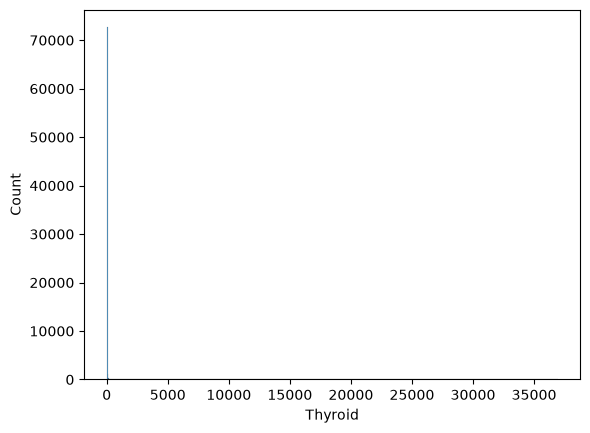

In [9]:
seaborn.histplot(df['Thyroid'])

In [10]:
df = numpy.log10(df)

/Users/sonalidash/miniforge3/envs/srpp_env/lib/python3.14/site-packages/pandas/core/internals/blocks.py:347: RuntimeWarning: divide by zero encountered in log10
  result = func(self.values, **kwargs)


<Axes: ylabel='Count'>

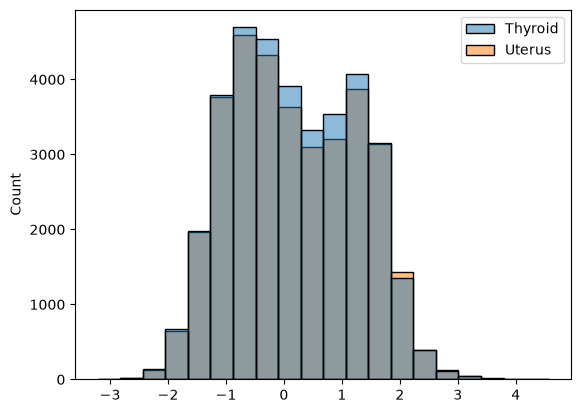

In [11]:
seaborn.histplot([df['Thyroid'], df['Uterus']], bins=20)

<Axes: xlabel='NOVA2', ylabel='TUBB'>

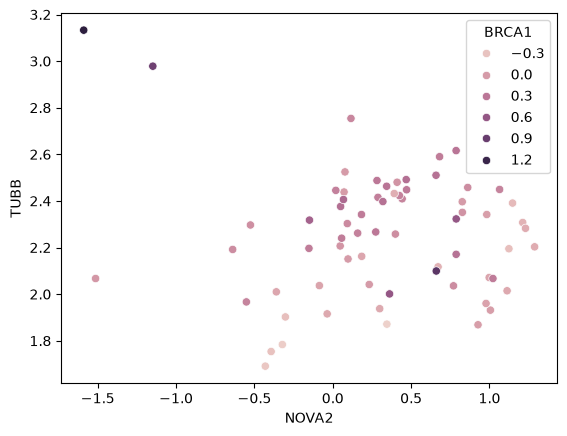

In [12]:
seaborn.scatterplot(x=df.loc['NOVA2'], y=df.loc['TUBB'], hue=df.loc['BRCA1'])

In [13]:
10 **df.loc['BRCA1']['Breast_Mammary_Tissue']

np.float64(1.18184)

In [14]:
df.columns

Index(['Adipose_Subcutaneous', 'Adipose_Visceral_Omentum', 'Adrenal_Gland',
       'Artery_Aorta', 'Artery_Coronary', 'Artery_Tibial', 'Bladder',
       'Brain_Amygdala', 'Brain_Anterior_cingulate_cortex_BA24',
       'Brain_Caudate_basal_ganglia', 'Brain_Cerebellar_Hemisphere',
       'Brain_Cerebellum', 'Brain_Cortex', 'Brain_Frontal_Cortex_BA9',
       'Brain_Hippocampus', 'Brain_Hypothalamus',
       'Brain_Nucleus_accumbens_basal_ganglia', 'Brain_Putamen_basal_ganglia',
       'Brain_Spinal_cord_cervical_c-1', 'Brain_Substantia_nigra',
       'Breast_Mammary_Tissue', 'Cells_Cultured_fibroblasts',
       'Cells_EBV-transformed_lymphocytes', 'Cervix_Ectocervix',
       'Cervix_Endocervix', 'Colon_Sigmoid', 'Colon_Transverse',
       'Colon_Transverse_Mixed_Cell', 'Colon_Transverse_Mucosa',
       'Colon_Transverse_Muscularis', 'Esophagus_Gastroesophageal_Junction',
       'Esophagus_Mucosa', 'Esophagus_Muscularis', 'Fallopian_Tube',
       'Heart_Atrial_Appendage', 'Heart_Left_Ventr

In [15]:
ann = pandas.read_csv('gencode.v47.annotation.chr22.gtf', sep='\t', header=None)

In [16]:
ann.head()

,0,1,2,3,4,5,6,7,8
0,chr22,HAVANA,gene,10524345,10529164,.,-,.,"gene_id ""ENSG00000294541.1""; gene_type ""lncRNA..."
1,chr22,HAVANA,transcript,10524345,10529164,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."
2,chr22,HAVANA,exon,10529036,10529164,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."
3,chr22,HAVANA,exon,10527853,10528040,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."
4,chr22,HAVANA,exon,10524345,10524446,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."


In [17]:
ann = ann.rename(columns={0:'chromosome',
1:'source',
2:'feature',
3:'start',
4:'end',
5:'idk',
6:'strand',
7:'idk2',
8:'description'})

In [18]:
chess = pandas.read_csv('chess3.1.3.annotation.chr22.gtf', sep='\t', header=None)

In [21]:
chess.head()

,0,1,2,3,4,5,6,7,8
0,chr22,CHESS,transcript,10685647,10688027,.,-,.,"transcript_id ""CHS.143381.1""; gene_id ""CHS.143..."
1,chr22,CHESS,exon,10685647,10685984,.,-,.,"transcript_id ""CHS.143381.1""; gene_id ""CHS.143..."
2,chr22,CHESS,exon,10687919,10688027,.,-,.,"transcript_id ""CHS.143381.1""; gene_id ""CHS.143..."
3,chr22,CHESS,CDS,10685662,10685984,.,-,2,"transcript_id ""CHS.143381.1""; gene_id ""CHS.143..."
4,chr22,CHESS,CDS,10687919,10687943,.,-,0,"transcript_id ""CHS.143381.1""; gene_id ""CHS.143..."


In [36]:
chess["gene_id"] = chess[8].str.split('gene_id "').str[1].str.split('"').str[0]

print("CHESS genes:", chess["gene_id"].nunique())
print("GENCODE genes:", (ann["feature"] == "gene").sum())

CHESS genes: 1290
GENCODE genes: 1748


In [37]:
print("CHESS transcripts:", (chess[2] == "transcript").sum())
print("GENCODE transcripts:", (ann["feature"] == "transcript").sum())

CHESS transcripts: 3399
GENCODE transcripts: 8237


In [38]:
chess_genes = chess["gene_id"].nunique()
chess_transcripts = (chess[2] == "transcript").sum()

print("Average transcripts per gene:", chess_transcripts / chess_genes)

Average transcripts per gene: 2.6348837209302327


In [39]:
chess_exons = chess[chess[2] == "exon"].copy()
gencode_exons = ann[ann["feature"] == "exon"].copy()

In [40]:
chess_exons["length"] = chess_exons[4] - chess_exons[3] + 1
gencode_exons["length"] = gencode_exons["end"] - gencode_exons["start"] + 1

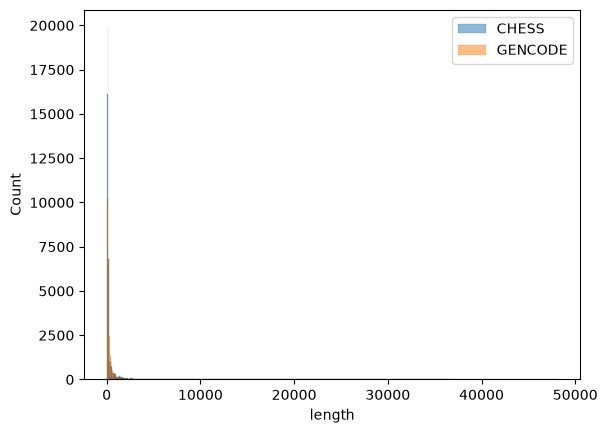

In [46]:
seaborn.histplot(chess_exons["length"], label="CHESS", alpha=0.5)
seaborn.histplot(gencode_exons["length"], label="GENCODE", alpha=0.5)

plt.legend()
plt.show()

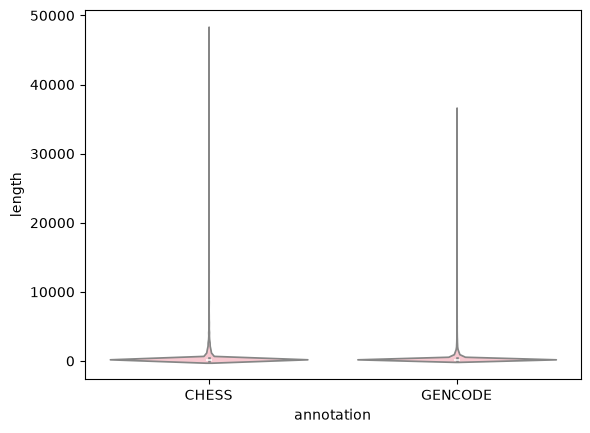

In [52]:
chess_exons["annotation"] = "CHESS"
gencode_exons["annotation"] = "GENCODE"

combined = pandas.concat([chess_exons, gencode_exons])

seaborn.violinplot(data=combined,x="annotation",y="length",color='pink')

plt.show()

In [49]:
chess_gene_sources = chess.drop_duplicates("gene_id")

print(chess_gene_sources[1].value_counts(normalize=True))

1
RefSeq     0.609302
CHESS      0.226357
MANE       0.120155
GENCODE    0.044186
Name: proportion, dtype: float64
